In [1]:
import glob
import os
import warnings
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import eigh, svd
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
os.makedirs("augsburg_figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 140
plt.rcParams["savefig.bbox"] = "tight"


def participation_ratio(vec):
  """Normalized Participation Ratio PR in [1/N, 1]."""
  v = np.asarray(vec, dtype=float)
  p = (v**2) / np.sum(v**2)
  return float(1.0 / (len(v) * np.sum(p**2)))


def bootstrap_pr_pair(X_raw, n_iter=300, frac=0.8, seed=42):
  """Bootstrap 95% confidence intervals for PR(u1) and PR(v1)."""
  rng = np.random.default_rng(seed)
  n_samples = len(X_raw)
  sub_size = int(frac * n_samples)
  pr_u, pr_v = [], []
  for _ in range(n_iter):
    idx = np.sort(rng.choice(n_samples, size=sub_size, replace=False))
    X_sub = X_raw[idx]
    X_z = (X_sub - X_sub.mean(axis=0)) / X_sub.std(axis=0)
    U_b, _, Vt_b = svd(X_z, full_matrices=False)
    pr_u.append(participation_ratio(U_b[:, 0]))
    pr_v.append(participation_ratio(Vt_b[0, :]))
  return (
      (float(np.percentile(pr_u, 2.5)), float(np.percentile(pr_u, 97.5))),
      (float(np.percentile(pr_v, 2.5)), float(np.percentile(pr_v, 97.5))),
  )


def build_lsym_u2(X_mat, k_nn=8):
  """Second Echelon: symmetric k-NN similarity graph and normalized Laplacian L_sym."""
  dist = squareform(pdist(X_mat, metric="euclidean"))
  sigma = float(np.median(dist[dist > 0]))
  W = np.exp(-(dist**2) / (2.0 * sigma**2))
  np.fill_diagonal(W, 0.0)
  n_nodes = len(W)
  for i in range(n_nodes):
    W[i, np.argsort(W[i])[::-1][k_nn:]] = 0.0
  W = 0.5 * (W + W.T)
  deg = np.sum(W, axis=1)
  d_inv = np.diag(1.0 / np.sqrt(np.maximum(deg, 1e-12)))
  L_sym = np.eye(n_nodes) - d_inv @ W @ d_inv
  evals, evecs = eigh(L_sym)
  u2 = evecs[:, 1]
  if u2.item(0) > u2.item(-1):
    u2 = -u2
  return u2, float(evals.item(1) - evals.item(0))


print("Spectral audit core initialized.")


Spectral audit core initialized.


In [2]:
archives = [
    f for f in os.listdir(".") if "ipvxmw" in f.lower() or f.endswith(".zip")
]
if not archives:
  raise FileNotFoundError(
      "Please upload 'doi-10.34894-ipvxmw.zip' to the Colab Files panel!"
  )

extract_dir = "allen_unger_data"
if not os.path.exists(extract_dir):
  with zipfile.ZipFile(archives.pop(0), "r") as z:
    z.extractall(extract_dir)

years_full = pd.Index(range(1500, 1701), name="Year")
yrs_d = years_full[1:]

# 1. Augsburg 8-Commodity Basket (excluding discontinuous Beer and Paper)
clean_basket = [
    "Barley",
    "Oats",
    "Salt",
    "Beef",
    "Oil",
    "Peas",
    "Flax",
    "Canvas",
]
nom_dict, ag_dict = {}, {}

for item in clean_basket:
  matches = glob.glob(f"{extract_dir}/**/Augsburg_{item}.csv", recursive=True)
  df_i = pd.read_csv(matches.pop(0), low_memory=False)
  df_i = df_i[(df_i["Year"] >= 1500) & (df_i["Year"] <= 1700)]
  nom_dict[item] = df_i.groupby("Year")["Original Value"].mean()
  ag_dict[item] = df_i.groupby("Year")["Standardized Value"].mean()

df_nom8 = pd.DataFrame(nom_dict, index=years_full).interpolate(
    limit_direction="both"
)
df_ag8 = pd.DataFrame(ag_dict, index=years_full).interpolate(
    limit_direction="both"
)

# 2. Central Europe 7-Market Grain Matrix
spatial_pairs = [
    ("Augsburg", "Barley"),
    ("Augsburg", "Oats"),
    ("Strasbourg", "Barley"),
    ("Strasbourg", "Rye"),
    ("Strasbourg", "Wheat"),
    ("Frankfurt", "Rye"),
    ("Munich", "Rye"),
]
sp_nom, sp_ag = {}, {}

for city, comm in spatial_pairs:
  matches = glob.glob(f"{extract_dir}/**/{city}_{comm}.csv", recursive=True)
  df_i = pd.read_csv(matches.pop(0), low_memory=False)
  df_i = df_i[(df_i["Year"] >= 1500) & (df_i["Year"] <= 1700)]
  col_id = f"{city}_{comm}"
  sp_nom[col_id] = df_i.groupby("Year")["Original Value"].mean()
  sp_ag[col_id] = df_i.groupby("Year")["Standardized Value"].mean()

df_sp_nom = pd.DataFrame(sp_nom, index=years_full).interpolate(
    limit_direction="both"
)
df_sp_ag = pd.DataFrame(sp_ag, index=years_full).interpolate(
    limit_direction="both"
)

# 3. Run Two-Echelon Spectral Audit across all 4 paired matrices
datasets_audit = [
    ("Augsburg 8-Basket (Nominal)", df_nom8),
    ("Augsburg 8-Basket (Silver)", df_ag8),
    ("Central Europe 7-Market (Nominal)", df_sp_nom),
    ("Central Europe 7-Market (Silver)", df_sp_ag),
]

audit_rows = []
u2_store = {}

for name, df_cur in datasets_audit:
  X = df_cur.values.astype(float)
  Z = (X - X.mean(axis=0)) / X.std(axis=0)
  U, S, Vt = svd(Z, full_matrices=False)
  en1 = float((S.item(0) ** 2) / np.sum(S**2) * 100)
  pr_u1 = participation_ratio(U[:, 0])
  pr_v1 = participation_ratio(Vt[0, :])
  ci_u1, ci_v1 = bootstrap_pr_pair(X, n_iter=300)

  dlog = np.diff(np.log(np.maximum(X, 1e-6)), axis=0)
  dlog_z = (dlog - dlog.mean(axis=0)) / dlog.std(axis=0)
  u2, gap = build_lsym_u2(dlog_z, k_nn=8)
  pr_u2 = participation_ratio(u2)
  u2_store[name] = u2

  min_p, best_yr = 1.0, None
  for idx in range(25, len(u2) - 25):
    _, p_val = mannwhitneyu(u2[:idx], u2[idx:], alternative="two-sided")
    if p_val < min_p:
      min_p, best_yr = float(p_val), int(yrs_d[idx])

  idx_b = int(np.searchsorted(yrs_d, best_yr))
  loo_p = {}
  for j, cname in enumerate(df_cur.columns):
    X_sub = np.delete(dlog_z, j, axis=1)
    u2_sub, _ = build_lsym_u2(X_sub, k_nn=8)
    _, p_s = mannwhitneyu(
        u2_sub[:idx_b], u2_sub[idx_b:], alternative="two-sided"
    )
    loo_p[cname] = float(p_s)
  worst_col = max(loo_p, key=loo_p.get)

  audit_rows.append({
      "Dataset": name,
      "Shape": f"{X.shape[0]} x {X.shape[1]}",
      "Mode1_Energy_%": round(en1, 2),
      "PR_u1": round(pr_u1, 3),
      "CI_u1": f"[{ci_u1[0]:.3f}, {ci_u1[1]:.3f}]",
      "PR_v1": round(pr_v1, 3),
      "CI_v1": f"[{ci_v1[0]:.3f}, {ci_v1[1]:.3f}]",
      "Lsym_Gap": round(gap, 4),
      "PR_u2": round(pr_u2, 3),
      "Best_Shift_Year": best_yr,
      "Min_MW_p": f"{min_p:.2e}",
      "LOO_Max_p": f"{loo_p[worst_col]:.2e} ({worst_col})",
  })

summary_augsburg = pd.DataFrame(audit_rows)
display(summary_augsburg)
summary_augsburg.to_csv(
    "augsburg_figures/augsburg_audit_summary.csv", index=False
)


,Dataset,Shape,Mode1_Energy_%,PR_u1,CI_u1,PR_v1,CI_v1,Lsym_Gap,PR_u2,Best_Shift_Year,Min_MW_p,LOO_Max_p
0,Augsburg 8-Basket (Nominal),201 x 8,75.61,0.061,"[0.049, 0.311]",0.959,"[0.923, 0.972]",0.0922,0.462,1674,1.57e-01,4.86e-01 (Flax)
1,Augsburg 8-Basket (Silver),201 x 8,68.72,0.039,"[0.031, 0.183]",0.908,"[0.868, 0.931]",0.0955,0.397,1674,1.51e-01,4.27e-01 (Flax)
2,Central Europe 7-Market (Nominal),201 x 7,70.79,0.170,"[0.149, 0.212]",0.972,"[0.961, 0.984]",0.0557,0.386,1672,7.17e-02,1.53e-01 (Augsburg_Oats)
3,Central Europe 7-Market (Silver),201 x 7,66.78,0.154,"[0.135, 0.201]",0.921,"[0.897, 0.961]",0.0582,0.392,1672,9.04e-02,1.24e-01 (Augsburg_Oats)


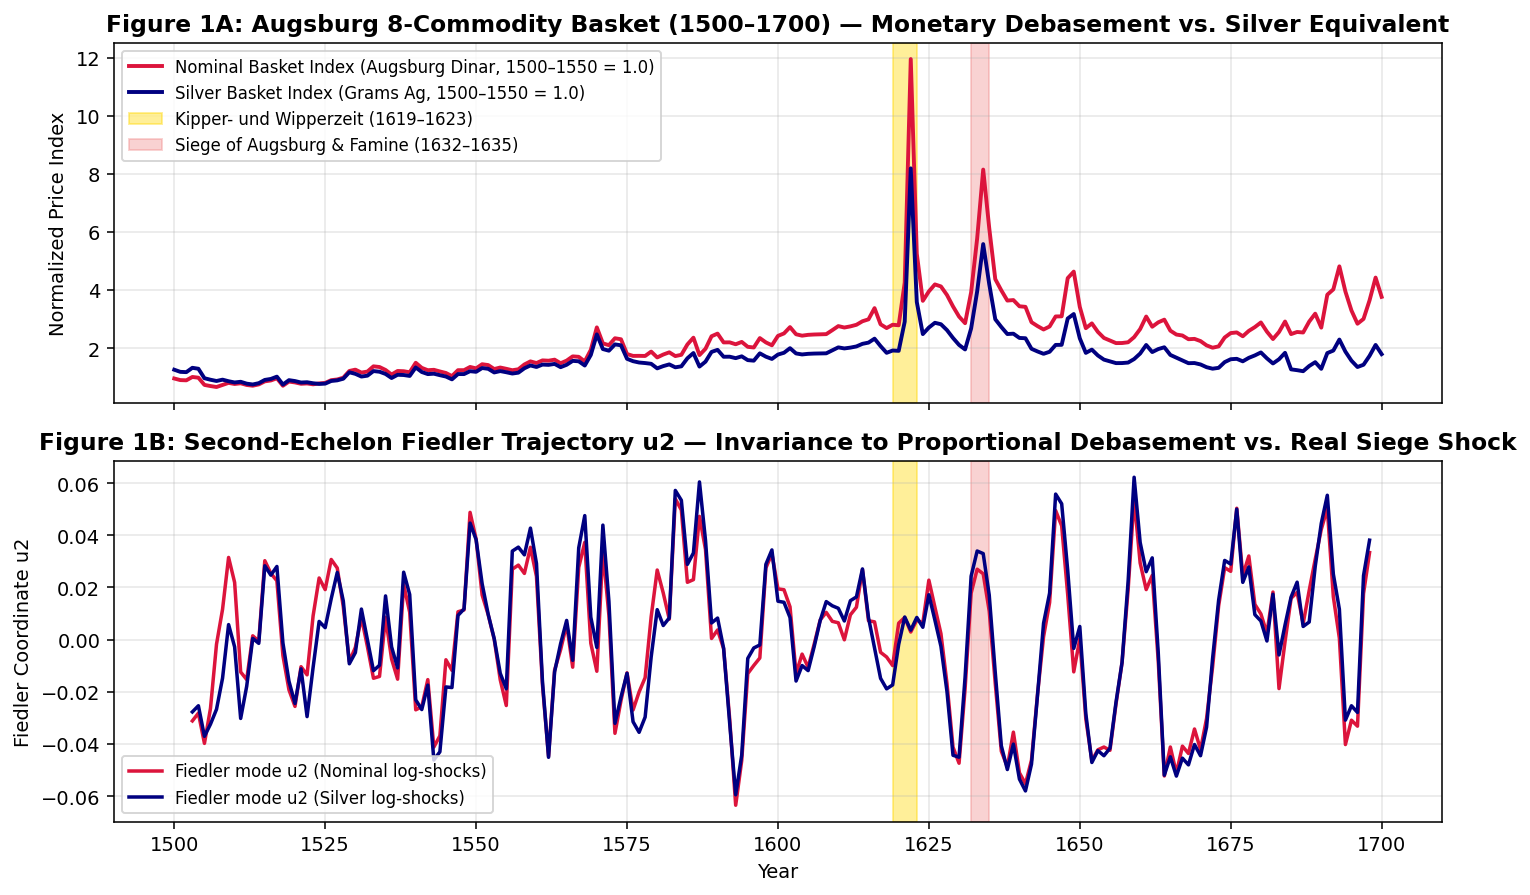

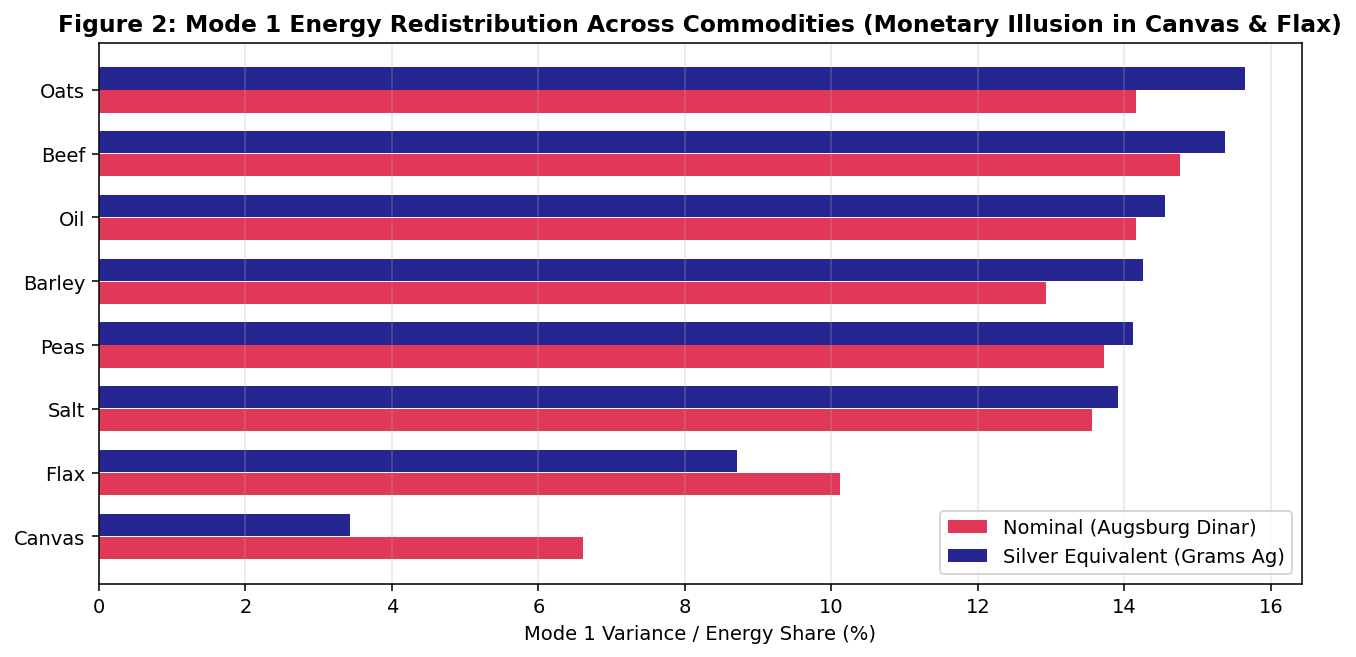

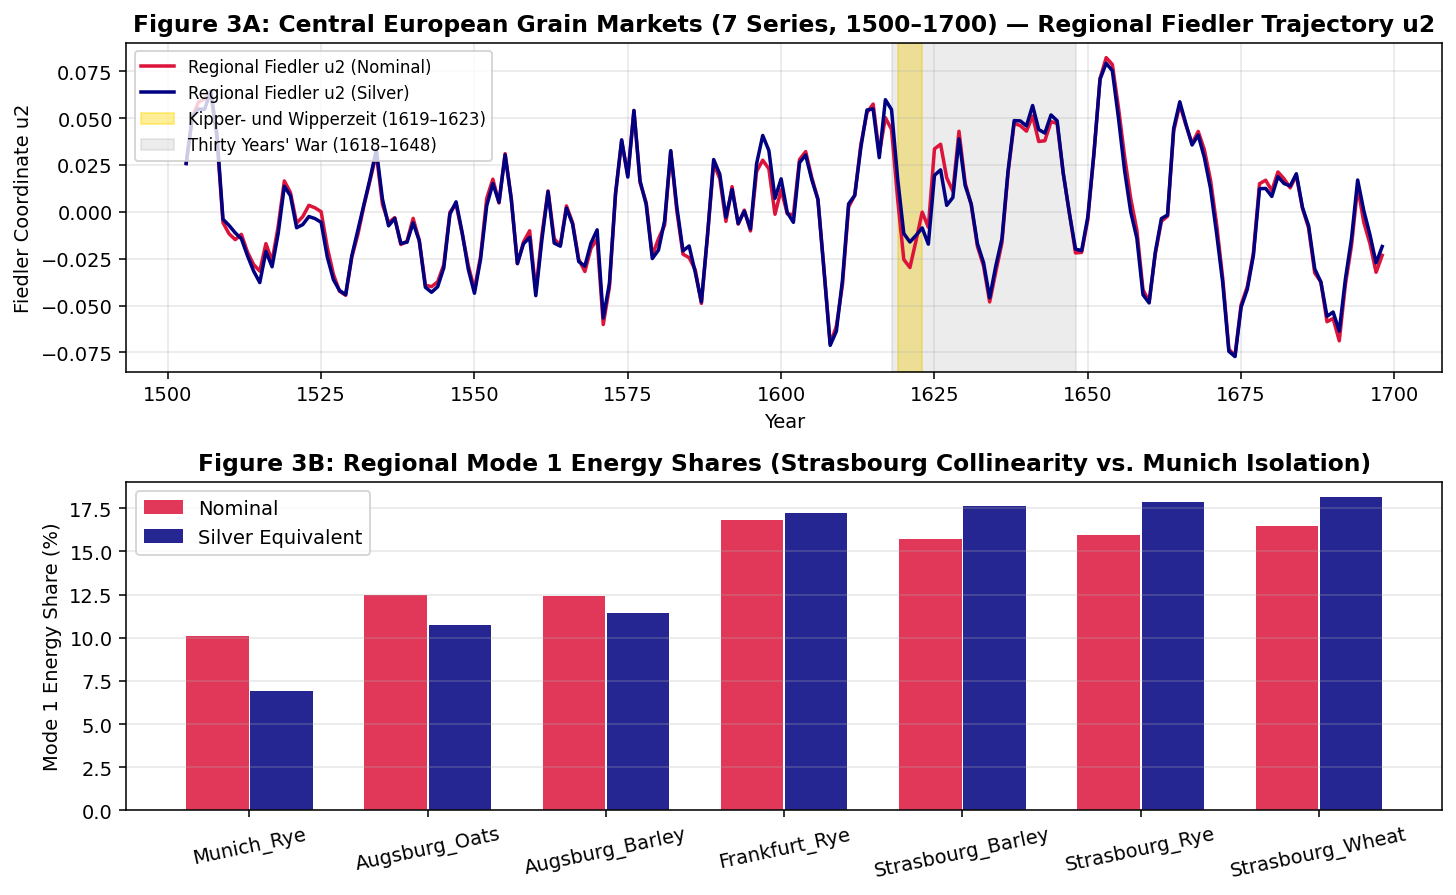

Clean notebook executed successfully. All outputs saved in 'augsburg_results_bundle.zip'.


In [3]:
if (
    np.dot(
        u2_store["Augsburg 8-Basket (Nominal)"],
        u2_store["Augsburg 8-Basket (Silver)"],
    )
    < 0
):
  u2_store["Augsburg 8-Basket (Nominal)"] = -u2_store[
      "Augsburg 8-Basket (Nominal)"
  ]
if (
    np.dot(
        u2_store["Central Europe 7-Market (Nominal)"],
        u2_store["Central Europe 7-Market (Silver)"],
    )
    < 0
):
  u2_store["Central Europe 7-Market (Nominal)"] = -u2_store[
      "Central Europe 7-Market (Nominal)"
  ]

# Figure 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.5), sharex=True)
ax1.plot(
    years_full,
    (df_nom8 / df_nom8.loc[1500:1550].mean()).mean(axis=1),
    color="crimson",
    lw=2.0,
    label="Nominal Basket Index (Augsburg Dinar, 1500–1550 = 1.0)",
)
ax1.plot(
    years_full,
    (df_ag8 / df_ag8.loc[1500:1550].mean()).mean(axis=1),
    color="navy",
    lw=2.0,
    label="Silver Basket Index (Grams Ag, 1500–1550 = 1.0)",
)
ax1.axvspan(
    1619,
    1623,
    color="gold",
    alpha=0.4,
    label="Kipper- und Wipperzeit (1619–1623)",
)
ax1.axvspan(
    1632,
    1635,
    color="lightcoral",
    alpha=0.35,
    label="Siege of Augsburg & Famine (1632–1635)",
)
ax1.set_title(
    "Figure 1A: Augsburg 8-Commodity Basket (1500–1700) — Monetary Debasement"
    " vs. Silver Equivalent",
    fontweight="bold",
)
ax1.set_ylabel("Normalized Price Index")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(True, alpha=0.3)

ax2.plot(
    yrs_d,
    pd.Series(u2_store["Augsburg 8-Basket (Nominal)"], index=yrs_d)
    .rolling(5, center=True)
    .mean(),
    color="crimson",
    lw=1.8,
    label="Fiedler mode u2 (Nominal log-shocks)",
)
ax2.plot(
    yrs_d,
    pd.Series(u2_store["Augsburg 8-Basket (Silver)"], index=yrs_d)
    .rolling(5, center=True)
    .mean(),
    color="navy",
    lw=1.8,
    label="Fiedler mode u2 (Silver log-shocks)",
)
ax2.axvspan(1619, 1623, color="gold", alpha=0.4)
ax2.axvspan(1632, 1635, color="lightcoral", alpha=0.35)
ax2.set_title(
    "Figure 1B: Second-Echelon Fiedler Trajectory u2 — Invariance to"
    " Proportional Debasement vs. Real Siege Shock",
    fontweight="bold",
)
ax2.set_ylabel("Fiedler Coordinate u2")
ax2.set_xlabel("Year")
ax2.legend(loc="lower left", fontsize=8.5)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "augsburg_figures/fig1_augsburg_basket_nominal_vs_silver.png", dpi=300
)
plt.show()

# Figure 2
Z_n = (df_nom8.values - df_nom8.values.mean(0)) / df_nom8.values.std(0)
_, _, Vt_n = svd(Z_n, full_matrices=False)
Z_a = (df_ag8.values - df_ag8.values.mean(0)) / df_ag8.values.std(0)
_, _, Vt_a = svd(Z_a, full_matrices=False)

sh_n = pd.Series(Vt_n[0, :] ** 2 * 100, index=clean_basket)
sh_a = pd.Series(Vt_a[0, :] ** 2 * 100, index=clean_basket)
order_items = sh_a.sort_values(ascending=True).index

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y_pos = np.arange(len(order_items))
ax.barh(
    y_pos - 0.18,
    sh_n[order_items],
    height=0.35,
    color="crimson",
    alpha=0.85,
    label="Nominal (Augsburg Dinar)",
)
ax.barh(
    y_pos + 0.18,
    sh_a[order_items],
    height=0.35,
    color="navy",
    alpha=0.85,
    label="Silver Equivalent (Grams Ag)",
)
ax.set_yticks(y_pos)
ax.set_yticklabels(order_items)
ax.set_xlabel("Mode 1 Variance / Energy Share (%)")
ax.set_title(
    "Figure 2: Mode 1 Energy Redistribution Across Commodities (Monetary"
    " Illusion in Canvas & Flax)",
    fontweight="bold",
)
ax.legend(loc="lower right")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("augsburg_figures/fig2_commodity_energy_redistribution.png", dpi=300)
plt.show()

# Figure 3
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.5))
ax1.plot(
    yrs_d,
    pd.Series(u2_store["Central Europe 7-Market (Nominal)"], index=yrs_d)
    .rolling(5, center=True)
    .mean(),
    color="crimson",
    lw=1.8,
    label="Regional Fiedler u2 (Nominal)",
)
ax1.plot(
    yrs_d,
    pd.Series(u2_store["Central Europe 7-Market (Silver)"], index=yrs_d)
    .rolling(5, center=True)
    .mean(),
    color="navy",
    lw=1.8,
    label="Regional Fiedler u2 (Silver)",
)
ax1.axvspan(
    1619,
    1623,
    color="gold",
    alpha=0.4,
    label="Kipper- und Wipperzeit (1619–1623)",
)
ax1.axvspan(
    1618,
    1648,
    color="gray",
    alpha=0.15,
    label="Thirty Years' War (1618–1648)",
)
ax1.set_title(
    "Figure 3A: Central European Grain Markets (7 Series, 1500–1700) —"
    " Regional Fiedler Trajectory u2",
    fontweight="bold",
)
ax1.set_ylabel("Fiedler Coordinate u2")
ax1.set_xlabel("Year")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(True, alpha=0.3)

Z_sn = (df_sp_nom.values - df_sp_nom.values.mean(0)) / df_sp_nom.values.std(0)
_, _, Vt_sn = svd(Z_sn, full_matrices=False)
Z_sa = (df_sp_ag.values - df_sp_ag.values.mean(0)) / df_sp_ag.values.std(0)
_, _, Vt_sa = svd(Z_sa, full_matrices=False)
sh_sn = pd.Series(Vt_sn[0, :] ** 2 * 100, index=df_sp_nom.columns)
sh_sa = pd.Series(Vt_sa[0, :] ** 2 * 100, index=df_sp_ag.columns)
ord_sp = sh_sa.sort_values(ascending=True).index

x_pos = np.arange(len(ord_sp))
ax2.bar(
    x_pos - 0.18,
    sh_sn[ord_sp],
    width=0.35,
    color="crimson",
    alpha=0.85,
    label="Nominal",
)
ax2.bar(
    x_pos + 0.18,
    sh_sa[ord_sp],
    width=0.35,
    color="navy",
    alpha=0.85,
    label="Silver Equivalent",
)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(ord_sp, rotation=12)
ax2.set_ylabel("Mode 1 Energy Share (%)")
ax2.set_title(
    "Figure 3B: Regional Mode 1 Energy Shares (Strasbourg Collinearity vs."
    " Munich Isolation)",
    fontweight="bold",
)
ax2.legend(loc="upper left")
ax2.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("augsburg_figures/fig3_central_europe_regional_audit.png", dpi=300)
plt.show()

with zipfile.ZipFile("augsburg_results_bundle.zip", "w") as zout:
  for f in glob.glob("augsburg_figures/*"):
    zout.write(f)

print(
    "Clean notebook executed successfully. All outputs saved in"
    " 'augsburg_results_bundle.zip'."
)
